# Feature Selection 
Shows feature elimination decisions

`results/feature_selection.csv`:
- Logged results in a table

`src/features/transformers.py`:
- Custom transformers implementing engineered features (e.g., lag
features, ratios, domain-driven encodings).

`src/features/preprocessing.py`:
- Main preprocessing pipeline that drops unused features, integrates
engineered features, and can be reused in modeling.


### Description of merging procedure
##### Groundwater nitrate data cleaning (`groundwater/gwater_clean.ipynb`)

### Preliminary Feature Assessment

Our updated integrated dataset contains **5,280 groundwater nitrate observations from 1,993 wells and 147 columns**, combining soil properties, terrain, climate, and historical agricultural land-use features. Agricultural predictors are linked to nitrate measurements using crop maps from the preceding year (2021–2024 for nitrate observations from 2022–2025). This one-year lag is a retrospective modeling assumption, not an established groundwater nitrate transport time.

Preliminary EDA identified consistently positive Spearman correlations between nitrate and **crop cycles (ρ = 0.350–0.390), multicrop area (ρ = 0.323–0.369), and vegetable/berry cultivation (ρ = 0.294–0.346)** across sampling years. However, agricultural predictors are strongly correlated with one another (e.g., crop cycles and multicrop area, ρ ≈ 0.90) and with geographic characteristics such as elevation and slope. These associations may reflect overlapping environmental and spatial patterns rather than independent effects.

We recommend retaining agricultural intensity, crop composition, soils, terrain, and climate as **candidate predictors** while excluding identifiers and inappropriate metadata from model inputs. Feature screening should be performed using training data only, with evaluation strategies accounting for repeated wells and spatial or temporal dependence. Highly correlated variables should be assessed for their additional predictive value rather than automatically removed. Final feature selection remains pending model evaluation.

#### Variables inside `notebooks/merge/groundwater_ml_integration_validation.csv`:

| Target  | Description |
|-------|-----|
| `nitrate_mg_L`		|			Nitrate concentration (mg/L) at specific geographic location and time |
|-------|-----|
| **Feature**  | ----- |
|-------|-----|
|`slopegradwta`			|		Weighted mean by intersected 500 m buffer area. |
|`brockdepmin`			|		Area-weighted depth to bedrock within 500 m. |
|`aws0150wta`				|	Area-weighted available water storage in 500 m. |
|`drclassdcd`				|	Convert drainage classes to mapped-area percentages. |
|`hydgrpdcd`			|	Convert hydrologic group classes to mapped-area percentages. |
|`soil_coverage_pct_500m`		|	Fraction of buffer with valid mapped soil data. |
|`elevation_m`				|	Sample existing 10 m DEM at well coordinates. |
|`distance_to_river_m`		|		Nearest mapped main-channel line; candidate stream order >3. |
|`topographic_position`			|	Well elevation minus mean DEM elevation within 500 m. |
|`pct_veg_berry_500m_2023`		|	Percent land 500m of the well w/ veggies, berries (2023) |
|`pct_grain_field_pasture_500m_2023`		|Percent land 500m of the well w/ grain, hay, pasture (2023) |
|`pct_idle_fallow_500m_2023`		|	Percent land 500m of the well idle or fallow (2023) |
|`pct_cropland_500m_2023`		|	Percent land 500m of the well farmed, all crops (2023) |
|`crop_cycles_500m_2023`		|	Avg crops planted per year on farmland 500m of well (2023) |
|`pct_vineyard_1000m_2023`		|	Percent land 1km of the well w/ vineyards (2023) |
|`pct_grain_field_pasture_1000m_2023`	| Percent land 1km of the well w/ grain, hay, pasture (2023) |
|`pct_idle_fallow_1000m_2023`	|	Percent land 1km of the well idle or fallow (2023) |
|`pct_multicrop_1000m_2023`	|		Percent land 1km of the well planted 2+ times a year (2023) |
|`dist_veg_berry_m_2023`		|	Distance (m) from well to nearest veggie/berry field (2023) |
|`precip_hist_mean_annual_mm`	|	Mean annual rainfall from complete years before sample; in→mm. |
|`precip_prev_3fullmonths_mm`	|	SUM of 3 whole months before sample month. |
|`precip_prev_12fullmonths_mm`|		SUM of 12 whole months before sample month. |
|`temp_hist_mean_c`			|	Historic mean of months before sample; °F→°C.|
|`temp_prev_3fullmonths_c`	|		MEAN temperature of previous 3 complete months.|
|`temp_prev_12fullmonths_c`	|		MEAN temperature of previous 12 complete months.|

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import geopandas as gpd

In [3]:
df = pd.read_csv("merge/groundwater_ml_integration_lag1_2021_2024_with_climate.csv")

In [4]:
df.columns

Index(['gm_well_id', 'gm_well_category', 'gm_samp_collection_date',
       'gm_latitude', 'gm_longitude', 'nitrate_mg_L', 'year', 'source_csv_row',
       'observation_id', 'soil_mapped_coverage_pct',
       ...
       'delta_cropland_pp_1000m', 'delta_multicrop_pp_1000m',
       'delta_dwr_polygon_footprint_pp_1000m', 'crop_source_match',
       'historical_mean_annual_precip_mm',
       'previous_3_complete_months_precip_mm',
       'previous_12_complete_months_precip_mm',
       'historical_mean_temperature_c',
       'previous_3_complete_months_temperature_c',
       'previous_12_complete_months_temperature_c'],
      dtype='object', length=147)

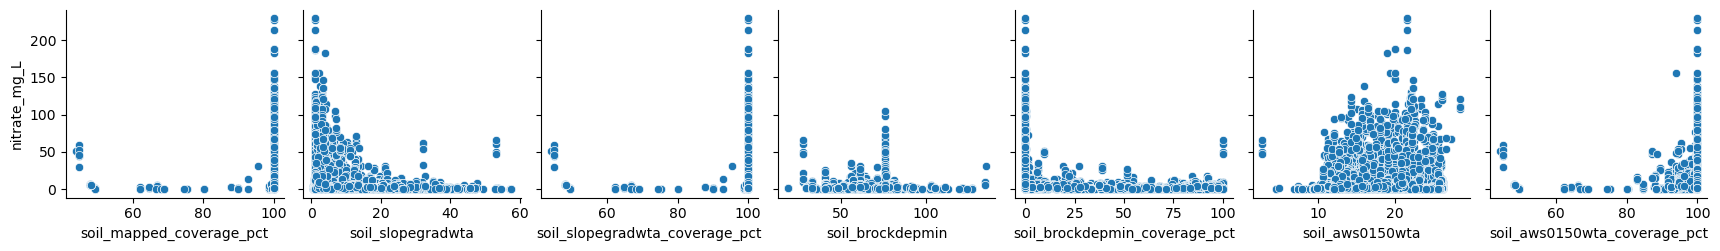

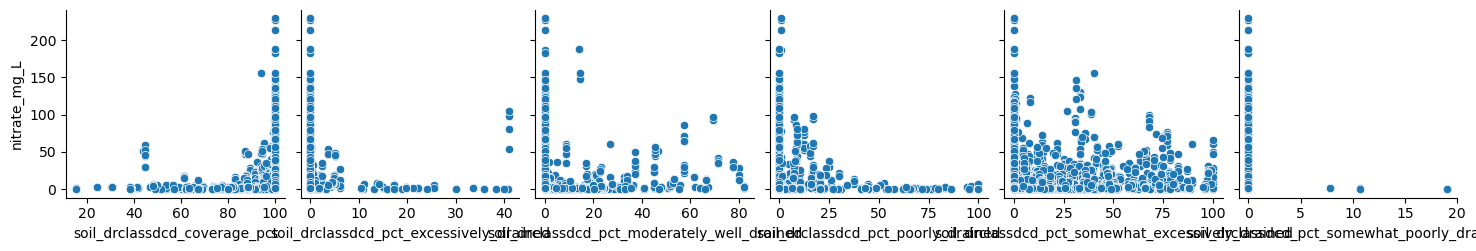

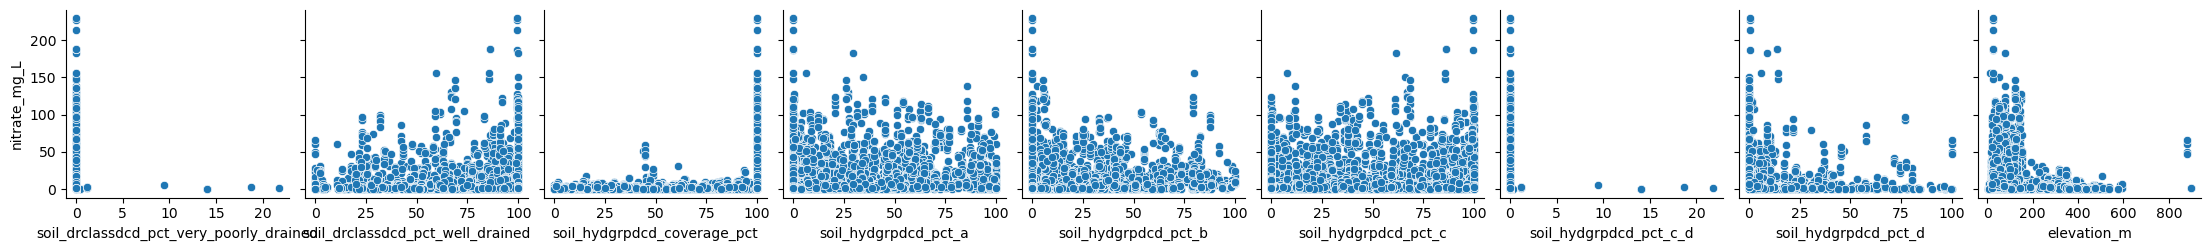

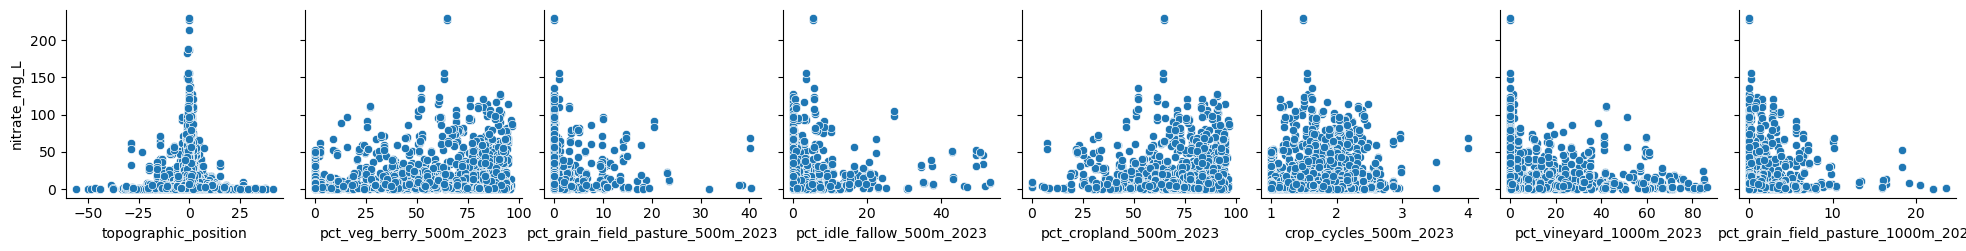

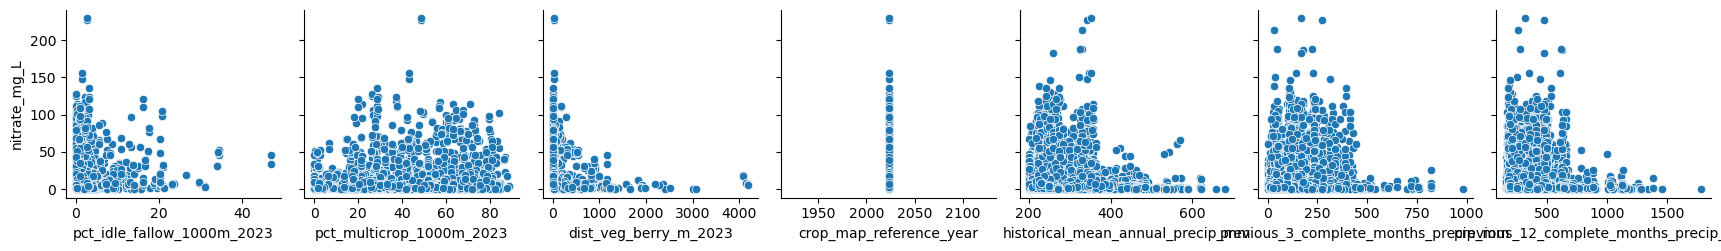

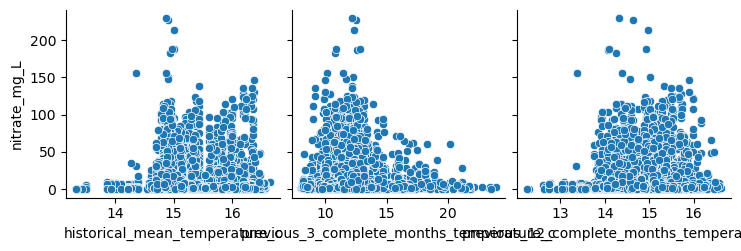

In [11]:
features1=['soil_mapped_coverage_pct', 'soil_slopegradwta',
       'soil_slopegradwta_coverage_pct', 'soil_brockdepmin',
       'soil_brockdepmin_coverage_pct', 'soil_aws0150wta',
       'soil_aws0150wta_coverage_pct']

features2=['soil_drclassdcd_coverage_pct',
       'soil_drclassdcd_pct_excessively_drained',
       'soil_drclassdcd_pct_moderately_well_drained',
       'soil_drclassdcd_pct_poorly_drained',
       'soil_drclassdcd_pct_somewhat_excessively_drained',
       'soil_drclassdcd_pct_somewhat_poorly_drained']

features3=['soil_drclassdcd_pct_very_poorly_drained',
       'soil_drclassdcd_pct_well_drained', 'soil_hydgrpdcd_coverage_pct',
       'soil_hydgrpdcd_pct_a', 'soil_hydgrpdcd_pct_b', 'soil_hydgrpdcd_pct_c',
       'soil_hydgrpdcd_pct_c_d', 'soil_hydgrpdcd_pct_d', 'elevation_m']

features4=['topographic_position', 'pct_veg_berry_500m_2023',
       'pct_grain_field_pasture_500m_2023', 'pct_idle_fallow_500m_2023',
       'pct_cropland_500m_2023', 'crop_cycles_500m_2023',
       'pct_vineyard_1000m_2023', 'pct_grain_field_pasture_1000m_2023']

features5=['pct_idle_fallow_1000m_2023', 'pct_multicrop_1000m_2023',
       'dist_veg_berry_m_2023', 'crop_map_reference_year',
       'historical_mean_annual_precip_mm',
       'previous_3_complete_months_precip_mm',
       'previous_12_complete_months_precip_mm']

features6=['historical_mean_temperature_c',
       'previous_3_complete_months_temperature_c',
       'previous_12_complete_months_temperature_c']

sns.pairplot(df, x_vars=features1, y_vars="nitrate_mg_L")
sns.pairplot(df, x_vars=features2, y_vars="nitrate_mg_L")
sns.pairplot(df, x_vars=features3, y_vars="nitrate_mg_L")
sns.pairplot(df, x_vars=features4, y_vars="nitrate_mg_L")
sns.pairplot(df, x_vars=features5, y_vars="nitrate_mg_L")
sns.pairplot(df, x_vars=features6, y_vars="nitrate_mg_L")
